In [84]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from scipy.spatial import distance
from matplotlib import pyplot as plt
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from collections import Counter

train_data = pd.read_csv('DodgerLoopGame_TRAIN.txt', sep='\s+',header=None)

test_data = pd.read_csv('DodgerLoopGame_TEST.txt', sep='\s+', header=None)


In [85]:
train_data.head(5)

,0,1,2,3,4,5,6,7,8,9,...,279,280,281,282,283,284,285,286,287,288
0,1.0,7.0,3.0,6.0,11.0,8.0,6.0,6.0,10.0,4.0,...,12.0,5.0,9.0,4.0,4.0,6.0,9.0,5.0,16.0,8.0
1,1.0,9.0,10.0,5.0,7.0,10.0,9.0,5.0,6.0,8.0,...,8.0,5.0,4.0,8.0,6.0,11.0,5.0,8.0,9.0,6.0
2,1.0,12.0,18.0,11.0,11.0,19.0,17.0,4.0,6.0,8.0,...,10.0,9.0,11.0,8.0,4.0,7.0,3.0,6.0,3.0,6.0
3,1.0,11.0,9.0,11.0,12.0,8.0,8.0,5.0,8.0,8.0,...,17.0,16.0,10.0,7.0,10.0,11.0,12.0,13.0,7.0,10.0
4,1.0,12.0,9.0,11.0,7.0,12.0,14.0,10.0,10.0,10.0,...,4.0,7.0,9.0,11.0,6.0,9.0,7.0,10.0,4.0,9.0


In [86]:
#checking the lables for the data, 1 for class 1, and 2 for class 2
train_data[0].unique()

array([1., 2.])

In [87]:
#checking for Nah values
print(train_data.isnull().sum(axis=1))

0      0
1      0
2      0
3      0
4      0
5      0
6      0
7      2
8      0
9      0
10     0
11     0
12     0
13     0
14     0
15    36
16     0
17     0
18     0
19    27
dtype: int64


In [88]:
# Replace missing values temporarily with 0 to calculate distances
train_data_filled = train_data.fillna(0)
test_data_filled = test_data.fillna(0)

# Compute pairwise distances (Euclidean)
train_dist_matrix = pd.DataFrame(distance.cdist(train_data_filled, train_data_filled, metric='euclidean'))
test_dist_matrix = pd.DataFrame(distance.cdist(test_data_filled, test_data_filled, metric='euclidean'))

In [89]:
# Define a function to evaluate KNNImputer with cross-validation
def evaluate_knn_imputer(data, k_values, cv_splits=5):
    results = {}
    kf = KFold(n_splits=cv_splits, shuffle=True, random_state=42)

    for k in k_values:
        errors = []
        for data_idx in kf.split(data):
            # Split the dataset
            split_data = data.iloc[data_idx]

            # Create and fit the KNNImputer
            knn_imputer = KNNImputer(n_neighbors=k)
            data_imputed = knn_imputer.fit_transform(split_data)

            # Calculate reconstruction error (e.g., Mean Squared Error)
            original_data = data.iloc[data_idx].fillna(0).to_numpy()
            error = mean_squared_error(original_data, data_imputed)
            errors.append(error)

        # Average error across folds
        results[k] = np.mean(errors)

    return results

In [90]:
# Define the range of \( K \)-values to test
k_values = [2, 3, 4, 5, 6]

# Evaluate KNNImputer with different \( K \)-values
train_results = evaluate_knn_imputer(train_dist_matrix, k_values)
test_results = evaluate_knn_imputer(test_dist_matrix, k_values)

# Find the optimal K
optimal_k = min(train_results, key=train_results.get)
print("\nErrors for each K:", train_results)
print(f"Optimal K: {optimal_k}")


Errors for each K: {2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0}
Optimal K: 2


In [91]:
# Find the optimal K
optimal_k = min(test_results, key=test_results.get)
print("\nErrors for each K:", test_results)
print(f"Optimal K: {optimal_k}") 


Errors for each K: {2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0}
Optimal K: 2


In [92]:
# Create and fit the KNNImputer
knn_imputer = KNNImputer(n_neighbors=optimal_k)
train_imputed = pd.DataFrame(knn_imputer.fit_transform(train_data))
test_imputed = pd.DataFrame(knn_imputer.fit_transform(test_data))
train_imputed.isnull().sum(axis=1)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
dtype: int64

In [93]:
# Separate features and target variable before standardization
y_train = train_data.iloc[:, 0]    # The first column is the target
X_train = train_data.iloc[:, 1:]   # All other columns are features

y_test = test_data.iloc[:, 0]      # The first column is the target
X_test = test_data.iloc[:, 1:]     # All other columns are features

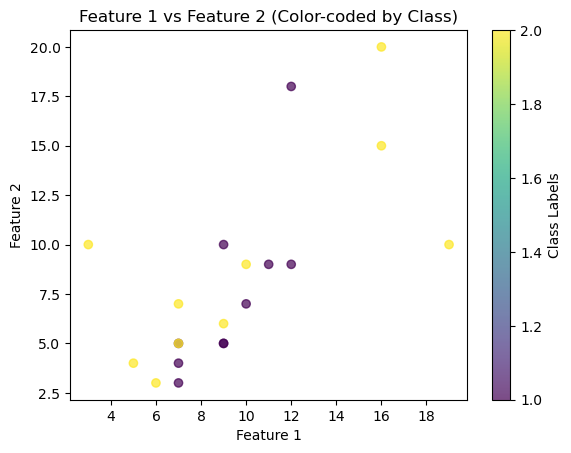

In [94]:
# Plot feature 1 vs feature 2, color-coded by class labels
plt.scatter(X_train.iloc[:, 0], X_train.iloc[:, 1], c=y_train, cmap="viridis", alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Feature 1 vs Feature 2 (Color-coded by Class)")
plt.colorbar(label="Class Labels")
plt.show()

In [95]:
# Standardization function
def standard_scaler(x_data, X_column):
    mean = np.mean(X_column)
    std_dev = np.std(X_column)
    return (x_data - mean) / std_dev

# Standardize the features only (do not standardize the target)
X_train_data_standardized = pd.DataFrame(
    {column: standard_scaler(X_train[column].values, X_train[column]) for column in X_train.columns}
)

X_test_data_standardized = pd.DataFrame(
    {column: standard_scaler(X_test[column].values, X_test[column]) for column in X_test.columns}
)

# Convert standardized data to numpy arrays for training
X_norm_train_data = X_train_data_standardized.values
X_norm_test_data = X_test_data_standardized.values


In [112]:
#K-Nearest Neighbors
#euclidean distance calculation
def euc_distance(x1, x2):
    return np.sqrt(np.sum((x1 -x2)**2))

class KNN:
    def __init__(self, k):
        self.k = k
        
    def fit(self, X, y):
        #storing the x, and y training data because we have no training stage
        self.X_train = X
        self.y_train = y
    
    def predict(self, X):
       
        predicted_labels = [self._predict(x) for x in X]
        return np.array(predicted_labels) #converting list into numpy
    
    #helper method   
    def _predict(self, x):
        # Compute the distance between x and all training samples
        distances = [euc_distance(x, x_train) for x_train in self.X_train]
    
        # Get indices of the k-nearest neighbors
        k_indices = np.argsort(distances)[:self.k]
    
        # Get the labels of the k-nearest neighbors
        k_nearest_labels = [self.y_train.iloc[i] if isinstance(self.y_train, pd.Series) else self.y_train[i] for i in k_indices]
    
        # Majority vote to determine the most common label
        most_common = Counter(k_nearest_labels).most_common(1)
        return most_common[0][0]  # Return the most common label

In [113]:
# Define a function to evaluate KNN classifier with cross-validation
def evaluate_knn_classifier(X, y, k_values, cv_splits=5):
    results = {}
    kf = KFold(n_splits=cv_splits, shuffle=True, random_state=42)

    for k in k_values:
        accuracies = []
        for train_index, test_index in kf.split(X):
            # Split data into training and validation sets
            X_train, X_val = X[train_index], X[test_index]
            y_train, y_val = y[train_index], y[test_index]

            # Create and train the KNN model
            model = KNN(k=k)
            model.fit(X_train, y_train)

            # Predict on validation data
            predictions = model.predict(X_val)

            # Calculate accuracy
            accuracy = np.sum(predictions == y_val) / len(y_val)
            accuracies.append(accuracy)

        # Average accuracy across folds
        results[k] = np.mean(accuracies)

    return results


In [114]:
# Assuming X_train and y_train are numpy arrays
k_values = [ 2 , 3, 5, 7, 9]  # List of k values to evaluate

results = evaluate_knn_classifier(X_norm_train_data, y_train, k_values)

# Print the results
for k, accuracy in results.items():
    print(f"k={k}: Accuracy={accuracy:.4f}")

# Find the best k
best_k = max(results, key=results.get)
print(f"Best k: {best_k} with accuracy: {results[best_k]:.4f}")


k=2: Accuracy=0.6500
k=3: Accuracy=0.5000
k=5: Accuracy=0.5000
k=7: Accuracy=0.4500
k=9: Accuracy=0.5000
Best k: 2 with accuracy: 0.6500


In [115]:
model = KNN(best_k)

learning = model.fit(X_norm_train_data, y_train)
prediction = model.predict(X_norm_test_data)

acc = np.sum(prediction == y_test)/ len(y_test)
print(acc)

0.8188405797101449


In [116]:
class TreeNode:
    def __init__(self, predicted_value=None, split_feature=None, threshold=None):
        self.predicted_value = predicted_value  # Value for leaf nodes
        self.split_feature = split_feature  # Feature index for splitting
        self.threshold = threshold  # Threshold for splitting
        self.left = None  # Left child
        self.right = None  # Right child


class DecisionTreeRegressor:
    def __init__(self, min_samples_split=2, max_depth=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.root = None  # Root of the tree

    def fit(self, X, y):
        self.root = self._build_tree(X, y)

    def _build_tree(self, X, y, depth=0):
        node = TreeNode()

        # Stopping criteria
        if len(y) < self.min_samples_split or (self.max_depth is not None and depth >= self.max_depth):
            node.predicted_value = np.mean(y)
            return node

        # Find the best feature and threshold to split
        best_feature, best_threshold, best_rss = self._find_best_split(X, y)
        if best_feature is None:  # No valid split
            node.predicted_value = np.mean(y)
            return node

        # Set the split details in the current node
        node.split_feature = best_feature
        node.threshold = best_threshold

        # Split the data
        left_mask = X[:, best_feature] <= best_threshold
        right_mask = X[:, best_feature] > best_threshold

        # Recursive calls for left and right child nodes
        node.left = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        node.right = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return node

    def _find_best_split(self, X, y):
        best_rss = float('inf')
        best_feature = None
        best_threshold = None

        n_features = X.shape[1]
        for feature in range(n_features):
            thresholds = np.unique(X[:, feature])
            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = X[:, feature] > threshold

                if left_mask.sum() == 0 or right_mask.sum() == 0:
                    continue

                rss = self._calculate_rss(y[left_mask], y[right_mask])
                if rss < best_rss:
                    best_rss = rss
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_rss

    def _calculate_rss(self, y_left, y_right):
        rss_left = np.var(y_left) * len(y_left) if len(y_left) > 0 else 0
        rss_right = np.var(y_right) * len(y_right) if len(y_right) > 0 else 0
        return rss_left + rss_right

    def predict(self, X):
        return np.array([self._predict_sample(sample, self.root) for sample in X])

    def _predict_sample(self, sample, node):
        if node.predicted_value is not None:  # Leaf node
            return node.predicted_value

        if sample[node.split_feature] <= node.threshold:
            return self._predict_sample(sample, node.left)
        else:
            return self._predict_sample(sample, node.right)


In [117]:
# Load the .data file
file_path = 'iris.data' 
df = pd.read_csv(file_path, delimiter=',', header=None) 
df.columns = ['x1', 'x2', 'x3', 'x4', 'y']# creating column names for the data
df.head(5)

,x1,x2,x3,x4,y
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [118]:
#checking on classes of labels
df['y'].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [119]:
# Replace non nunmerical lables to numbers
df['y'] = df['y'].replace({'Iris-setosa': 0, 'Iris-versicolor': 1 , 'Iris-virginica': 2})

# Split data (80% train, 20% test)
df_train = df.sample(frac=0.8, random_state=42)
df_test = df.drop(df_train.index)

df_X_train = df_train.iloc[:, :-1].values  # All columns except the last one as features
df_y_train = df_train.iloc[:, -1].values   # Last column as target
df_X_test = df_test.iloc[:, :-1].values
df_y_test = df_test.iloc[:, -1].values

In [123]:
# Fit the model
tree = DecisionTreeRegressor(min_samples_split=2, max_depth=3)
tree.fit(df_X_train, df_y_train)

# Predict
predictions = tree.predict(df_X_test)

print("Predictions:", predictions)


Predictions: [0.  0.  0.  0.  0.  0.  0.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
 2.  2.  1.  2.  2.  2.  2.  1.6 2.  2.  2.  2. ]


In [124]:
def mse(y, y_hat):
    return np.mean((y - y_hat)**2)

In [125]:
error = mse(df_y_test, predictions)
print(f'Error: {error}')

Error: 0.03866666666666666
